# Task 2 - Data Understanding and Data Preparation

**Quarterly emergency-resource planning for weekends and holidays**

> Each quater, we forecast how many accidents with injuries or fatalities each of Brazil's 5 macro-regions will have on every weekend day and holiday of the next quarter. Regional emergency planner will use the forcast to decide how many ambulances, rescue team and patrols to have ready. **The model** count total accidents with injuries and fatality per region per day. The forecast is made **1 motnth before the quarter starts**.


**Contents**
1. Set up and decisions carried over from Task 1
2. Data structure and quality
3. Monthly trend
4. Holiday and weekend calendar
5. Region


-------
## 1. Set up and decisions carried over from Task 1

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dateutil.easter import easter
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest

DATA = Path("highway_accidents.csv")
OUT = Path("data/processed")
OUT.mkdir(parents=True, exist_ok=True)

# ---- decisions agreed in Task 1 ----
LEAD_MONTHS = 1         # data cutoff (ref_date) = 1 month before the quarter starts
WINDOW_DAYS = 3         # holiday window = holiday date +/- 3 days
QUARTER_DAYS = 91       # "last quarter" = the 91 days up to the cutoff
# Target = accidents with victims = injury (1) or fatal (2) per region per day. Class 0 is excluded. 

REGIONS = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]

# plotting: restrained palette, light grid, no top/right spines
BLUE, ORANGE, GREY, DARK = "#2F6DB5", "#D9622B", "#8A8F98", "#222222"
REGION_COLORS = dict(zip(REGIONS, [BLUE, ORANGE, "#1B998B", "#7A5FB5", "#C79A1E"]))
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E3E5E8", "grid.linewidth": 0.7, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": DARK, "text.color": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "legend.frameon": False, "figure.figsize": (8, 3.6),
})
pd.set_option("display.max_columns", 50, "display.width", 140, "display.float_format", "{:,.3f}".format)

--------
## 2. Data structure and quality

In [2]:
raw = pd.read_csv(DATA, parse_dates=["date"])
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns | {raw.date.min().date()} to {raw.date.max().date()} | sorted by date: {raw.date.is_monotonic_increasing}")
raw.head()

150,000 rows x 23 columns | 2007-01-01 to 2025-12-31 | sorted by date: True


,date,km,road_direction,roadway_type,area_type,latitude,longitude,time_of_day,highway_type,Uphill,Crossing,Curve,Downhill,Temporary_Detour,Roadworks,Road_Intersection,Bridge,Straight,Regulated_Uturn,Roundabout,Tunnel,Overpass,accident_classification
0,2007-01-01,45.500,1.000,0.000,0.000,NaN,NaN,0,3.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0
1,2007-01-01,83.900,1.000,0.000,1.000,NaN,NaN,1,3.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1
2,2007-01-01,11.000,0.000,0.000,0.000,NaN,NaN,3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0
3,2007-01-01,180.000,1.000,2.000,1.000,NaN,NaN,0,4.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1
4,2007-01-01,230.600,0.000,2.000,0.000,NaN,NaN,0,3.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0


In [3]:
raw.dtypes

date                       datetime64[us]
km                                float64
road_direction                    float64
roadway_type                      float64
area_type                         float64
latitude                          float64
longitude                         float64
time_of_day                         int64
highway_type                      float64
Uphill                            float64
Crossing                          float64
Curve                             float64
Downhill                          float64
Temporary_Detour                  float64
Roadworks                         float64
Road_Intersection                 float64
Bridge                            float64
Straight                          float64
Regulated_Uturn                   float64
Roundabout                        float64
Tunnel                            float64
Overpass                          float64
accident_classification             int64
dtype: object

### 2.1 Missing Values Checks

In [4]:
roles = {
    "date": "calendar key (known in advance)",
    "km": "quality checks only (no use as input: unreliable, accident-level)",
    "road_direction": "not used",
    "roadway_type": "severity context, kept in accidents.csv",
    "area_type": "severity context, kept in accidents.csv",
    "latitude": "mapping to macro-region only",
    "longitude": "mapping to macro-region only",
    "time_of_day": "severity context, kept in accidents.csv",
    "highway_type": "not used for now",
    "accident_classification": "TARGET: class 1 or 2 counts as an accident with victims; class 0 (no injury) is excluded",
}
for c in raw.columns[9:-1]:
    roles[c] = "severity context, kept in accidents.csv" if c in ["Curve", "Roadworks"] else "accident-level road feature: aggregate or drop"
dictionary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": raw.isna().mean() * 100,
    "unique": raw.nunique(),
    "role": pd.Series(roles),
})
dictionary

,dtype,missing,missing_%,unique,role
Bridge,float64,1,0.001,2,accident-level road feature: aggregate or drop
Crossing,float64,1,0.001,2,accident-level road feature: aggregate or drop
Curve,float64,1,0.001,2,"severity context, kept in accidents.csv"
Downhill,float64,1,0.001,2,accident-level road feature: aggregate or drop
Overpass,float64,1,0.001,2,accident-level road feature: aggregate or drop
Regulated_Uturn,float64,1,0.001,2,accident-level road feature: aggregate or drop
Road_Intersection,float64,1,0.001,2,accident-level road feature: aggregate or drop
Roadworks,float64,1,0.001,2,"severity context, kept in accidents.csv"
Roundabout,float64,1,0.001,2,accident-level road feature: aggregate or drop
Straight,float64,1,0.001,2,accident-level road feature: aggregate or drop


In [5]:
missing = raw[raw.latitude.isna() | raw.longitude.isna()]
present = raw[raw.latitude.notna() & raw.longitude.notna()]

print(f"Missing coordinates: {len(missing):,} rows | {missing.date.min().date()} to {missing.date.max().date()}")
print(f"Present coordinates: {len(present):,} rows | {present.date.min().date()} to {present.date.max().date()}")
print("rows with a missing road_direction missing:", raw.road_direction.isna().sum())

Missing coordinates: 106,237 rows | 2007-01-01 to 2016-12-31
Present coordinates: 43,763 rows | 2017-01-01 to 2025-12-31
rows with a missing road_direction missing: 90


**Decision** Use Data from 2017 to 2025 for regional prediction

### 2.2 Coordinates, Km, Duplicates

coordinates outside the Brazil bounding box: 3


,date,latitude,longitude,km
106275,2017-01-02,0.000,0.000,418.000
106352,2017-01-07,13.000,40.000,658.000
106364,2017-01-07,-85.049,-40.000,827.000


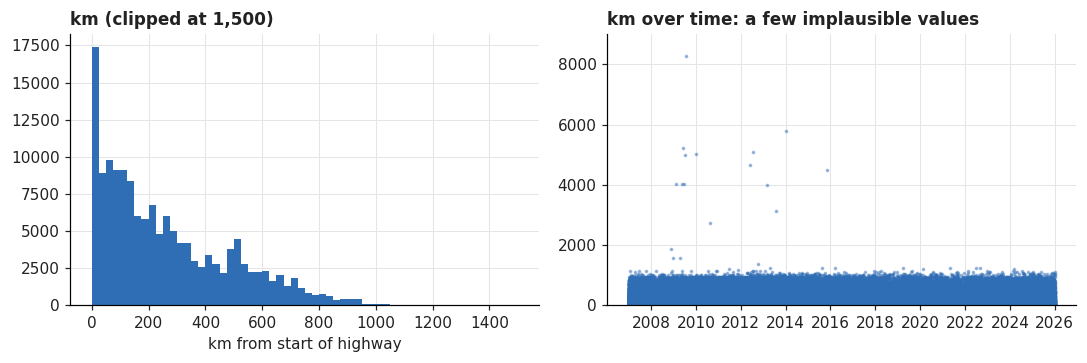

km quantiles: {0.5: 202.0, 0.9: 603.0, 0.99: 886.0, 0.999: 1033.0} max: 8280.0
km > 1,100 (above the 99.9th percentile): 71 rows; the longest federal highways are about 4,500 km, so values above that are errors
exact duplicate rows: 49 (no accident ID, so two real accidents at the same km on the same day look identical)


In [6]:
c = raw.dropna(subset=["latitude"])
inside = c.latitude.between(-34, 6) & c.longitude.between(-74, -32)
print(f"coordinates outside the Brazil bounding box: {(~inside).sum()}")
display(c.loc[~inside, ["date", "latitude", "longitude", "km"]])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(raw.km.clip(upper=1500), bins=60, color=BLUE)
axes[0].set(title="km (clipped at 1,500)", xlabel="km from start of highway")
axes[1].scatter(raw.date, raw.km, s=2, color=BLUE, alpha=0.4)
axes[1].set(title="km over time: a few implausible values", ylim=(0, 9000))
plt.tight_layout(); plt.show()

print("km quantiles:", raw.km.quantile([.5, .9, .99, .999]).round(0).to_dict(), "max:", raw.km.max())
print(f"km > 1,100 (above the 99.9th percentile): {(raw.km > 1100).sum()} rows; the longest federal highways are about 4,500 km, so values above that are errors")
print(f"exact duplicate rows: {raw.duplicated().sum()} (no accident ID, so two real accidents at the same km on the same day look identical)")

- **Invalid coordinates:** 3 rows (e.g. latitude −85, longitude 40, or 0/0). They are set to missing, not mapped.
- **`km`** has values up to 8,280 and a handful above any real highway length. We never use `km` as an input; outliers are only flagged.
- **Duplicates:** 49 exact duplicates. Without an accident ID we cannot tell a double entry from two accidents at the same spot, and 49 of 150,000 is negligible, so they are **kept**.

## 3. Monthly trend

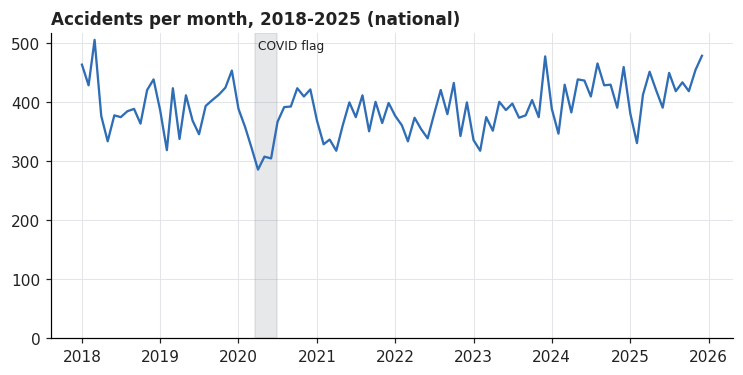

date,2019-10-01,2019-11-01,2019-12-01,2020-01-01,2020-02-01,2020-03-01,2020-04-01,2020-05-01,2020-06-01,2020-07-01,2020-08-01,2020-09-01,2020-10-01,2020-11-01,2020-12-01,2021-01-01,2021-02-01,2021-03-01
accidents,413,425,454,389,358,324,286,308,305,367,392,393,424,410,422,369,329,337


In [7]:
monthly = raw[raw.date >= "2018-01-01"].groupby(raw.date.dt.to_period("M")).size()
monthly.index = monthly.index.to_timestamp()
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly, color=BLUE)
ax.axvspan(pd.Timestamp("2020-03-16"), pd.Timestamp("2020-06-30"), color=GREY, alpha=0.2)
ax.text(pd.Timestamp("2020-04-01"), monthly.max() * 0.97, "COVID flag", fontsize=8)
ax.set(title="Accidents per month, 2018-2025 (national)", ylim=(0, None))
plt.show()
monthly["2019-10":"2021-03"].to_frame("accidents").T

During Covide time, the volume was around 15-20% lower in March, April, May and June 2020 compare with 2019

## 4. Holiday and weekend calendar

The model forecasts weekends and holidays, so we need a calendar that marks them. We build one table with **one row per day**, from 2017 to 2026 (the modelling years plus the forecast year).


In [8]:
# If the package is missing, run once:  %pip install holidays
import holidays as pyholidays

CAL_START, CAL_END = "2017-01-01", "2026-12-31"   # modelling years + the forecast year

# Optional days from the package that are NOT a full day off, so we skip them
SKIP_HOLIDAYS = ("Ash Wednesday", "Public Servant's Day", "Christmas Eve", "New Year's Eve")


def get_brazil_holidays(first_year, last_year):
    """Return a Series: date -> holiday name (national holidays + Carnival + Corpus Christi)."""
    found = pyholidays.country_holidays("BR", years=range(first_year, last_year + 1),
                                        categories=("public", "optional"))
    names = pd.Series({pd.Timestamp(d): n for d, n in found.items()}).sort_index()
    return names[~names.str.startswith(SKIP_HOLIDAYS)]


def build_calendar(start, end, window=WINDOW_DAYS):
    dates = pd.date_range(start, end, freq="D")
    cal = pd.DataFrame({"date": dates})

    # --- basic date parts ---
    cal["year"] = dates.year
    cal["quarter"] = dates.quarter
    cal["month"] = dates.month
    cal["day"] = dates.day
    cal["day_of_week"] = dates.day_name()
    cal["is_weekend"] = (dates.dayofweek >= 5).astype(int)      # Saturday or Sunday

    # --- holidays ---
    # We load one extra year before and after, so days at the edge of the calendar
    # (for example 1 January) can still find their nearest holiday.
    hol = get_brazil_holidays(dates.year.min() - 1, dates.year.max() + 1)
    cal["holiday_name"] = cal["date"].map(hol)
    cal["is_holiday"] = cal["holiday_name"].notna().astype(int)

    # --- days before the next holiday and days after the last holiday ---
    hol_days = hol.index.to_numpy().astype("datetime64[D]")
    day = dates.to_numpy().astype("datetime64[D]")

    next_pos = np.searchsorted(hol_days, day, side="left")        # first holiday on or after this day
    prev_pos = np.searchsorted(hol_days, day, side="right") - 1   # last holiday on or before this day
    to_next = (hol_days[next_pos] - day).astype(int)
    since_last = (day - hol_days[prev_pos]).astype(int)

    # 0 = the holiday itself. Empty (NaN) when the holiday is more than `window` days away.
    cal["days_to_holiday"] = pd.Series(to_next).where(lambda s: s <= window).astype("Int64")
    cal["days_after_holiday"] = pd.Series(since_last).where(lambda s: s <= window).astype("Int64")
    cal["is_holiday_window"] = (cal["days_to_holiday"].notna() | cal["days_after_holiday"].notna()).astype(int)

    # --- bridge day ("ponte") ---
    # A working day between a holiday and the weekend. Many people take it off.
    # Monday before a Tuesday holiday, or Friday after a Thursday holiday.
    hol_flag = cal["is_holiday"]
    monday_bridge = (cal["day_of_week"] == "Monday") & (hol_flag.shift(-1, fill_value=0) == 1)
    friday_bridge = (cal["day_of_week"] == "Friday") & (hol_flag.shift(1, fill_value=0) == 1)
    cal["is_bridge_day"] = ((monday_bridge | friday_bridge) & (hol_flag == 0)).astype(int)

    # --- long weekend ---
    # A block of 3 or more days off in a row (weekend, holiday, bridge day)
    # that contains at least one holiday or bridge day. A normal weekend is not a long weekend.
    day_off = (cal["is_weekend"] == 1) | (hol_flag == 1) | (cal["is_bridge_day"] == 1)
    block = (day_off != day_off.shift()).cumsum()                 # new number each time the pattern changes
    block_size = day_off.groupby(block).transform("size")
    has_extra = ((hol_flag == 1) | (cal["is_bridge_day"] == 1)).groupby(block).transform("max")
    cal["is_long_weekend"] = (day_off & (block_size >= 3) & has_extra).astype(int)

    # --- school vacation: July, January, and the second half of December ---
    cal["is_school_vacation"] = (cal["month"].isin([1, 7]) | ((cal["month"] == 12) & (cal["day"] >= 15))).astype(int)

    return cal


calendar = build_calendar(CAL_START, CAL_END)
calendar.to_csv(OUT / "holidays_calendar.csv", index=False)
print(f"Saved {OUT / 'holidays_calendar.csv'}: {calendar.shape[0]:,} rows x {calendar.shape[1]} columns")
calendar.head(10)

Saved data/processed/holidays_calendar.csv: 3,652 rows x 15 columns


,date,year,quarter,month,day,day_of_week,is_weekend,holiday_name,is_holiday,days_to_holiday,days_after_holiday,is_holiday_window,is_bridge_day,is_long_weekend,is_school_vacation
0,2017-01-01,2017,1,1,1,Sunday,1,Universal Fraternization Day,1,0,0,1,0,0,1
1,2017-01-02,2017,1,1,2,Monday,0,NaN,0,<NA>,1,1,0,0,1
2,2017-01-03,2017,1,1,3,Tuesday,0,NaN,0,<NA>,2,1,0,0,1
3,2017-01-04,2017,1,1,4,Wednesday,0,NaN,0,<NA>,3,1,0,0,1
4,2017-01-05,2017,1,1,5,Thursday,0,NaN,0,<NA>,<NA>,0,0,0,1
5,2017-01-06,2017,1,1,6,Friday,0,NaN,0,<NA>,<NA>,0,0,0,1
6,2017-01-07,2017,1,1,7,Saturday,1,NaN,0,<NA>,<NA>,0,0,0,1
7,2017-01-08,2017,1,1,8,Sunday,1,NaN,0,<NA>,<NA>,0,0,0,1
8,2017-01-09,2017,1,1,9,Monday,0,NaN,0,<NA>,<NA>,0,0,0,1
9,2017-01-10,2017,1,1,10,Tuesday,0,NaN,0,<NA>,<NA>,0,0,0,1


In [9]:
# Quick checks on the calendar
assert calendar["date"].is_unique, "duplicate dates"
assert len(calendar) == (pd.Timestamp(CAL_END) - pd.Timestamp(CAL_START)).days + 1, "missing dates"

per_year = calendar.groupby("year").agg(
    weekend_days=("is_weekend", "sum"),
    holidays=("is_holiday", "sum"),
    holidays_on_weekdays=("is_holiday", lambda s: int(((s == 1) & (calendar.loc[s.index, "is_weekend"] == 0)).sum())),
    holiday_window_days=("is_holiday_window", "sum"),
    long_weekend_days=("is_long_weekend", "sum"),
)
display(per_year.T)

# Example: Carnival 2024. The window columns should count down to the holiday and up after it.
calendar.loc[calendar["date"].between("2024-02-07", "2024-02-18"),
             ["date", "day_of_week", "holiday_name", "is_holiday", "days_to_holiday",
              "days_after_holiday", "is_holiday_window", "is_long_weekend"]]

year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
weekend_days,105,104,104,104,104,105,105,104,104,104
holidays,12,12,12,12,12,12,12,13,13,13
holidays_on_weekdays,11,11,8,11,10,9,11,9,9,12
holiday_window_days,78,78,73,78,78,77,78,83,79,83
long_weekend_days,34,36,15,30,29,19,34,15,24,37


,date,day_of_week,holiday_name,is_holiday,days_to_holiday,days_after_holiday,is_holiday_window,is_long_weekend
2593,2024-02-07,Wednesday,NaN,0,<NA>,<NA>,0,0
2594,2024-02-08,Thursday,NaN,0,<NA>,<NA>,0,0
2595,2024-02-09,Friday,NaN,0,3,<NA>,1,0
2596,2024-02-10,Saturday,NaN,0,2,<NA>,1,1
2597,2024-02-11,Sunday,NaN,0,1,<NA>,1,1
2598,2024-02-12,Monday,Carnival,1,0,0,1,1
2599,2024-02-13,Tuesday,Carnival,1,0,0,1,1
2600,2024-02-14,Wednesday,NaN,0,<NA>,1,1,0
2601,2024-02-15,Thursday,NaN,0,<NA>,2,1,0
2602,2024-02-16,Friday,NaN,0,<NA>,3,1,0


### 4.1 Do weekends and holidays have more accidents?

Before we trust the calendar, we check if it explains the accident counts. We count the accidents with injuries or deaths per day (the target) and compare the day types.


,days,avg_per_day,vs_normal_weekday_%
day_type,,,
Normal weekday,1529,10.057,0.000
Day near a holiday,347,10.447,3.876
Weekend,779,11.954,18.862
Holiday (on a weekday),70,10.057,0.002


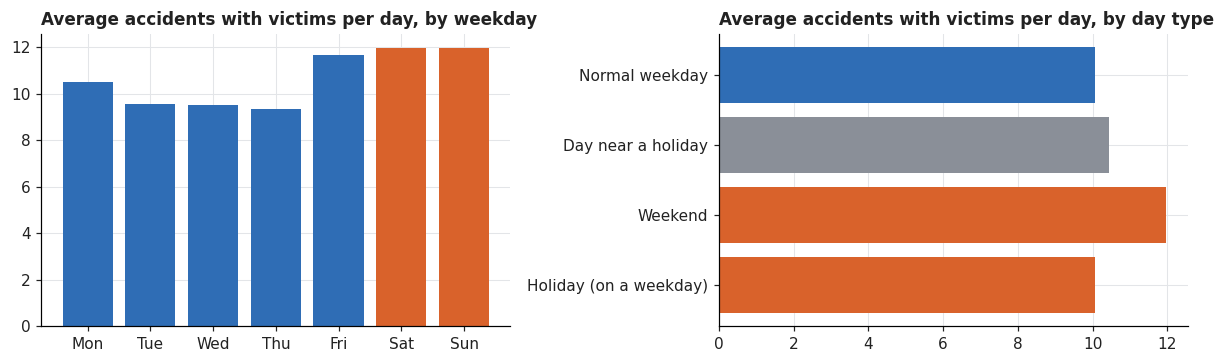

In [10]:
ERA_START = pd.Timestamp("2018-04-01")        

# Target: accidents with injury (1) or death (2). Class 0 is excluded.
victims = raw[(raw["accident_classification"] >= 1) & (raw["date"] >= ERA_START)]

# One row per day. Days with no accident are kept with a count of 0.
all_days = pd.date_range(ERA_START, "2025-12-31", freq="D")
daily = (victims.groupby("date").size().reindex(all_days, fill_value=0)
         .rename("accidents").rename_axis("date").reset_index())
daily = daily.merge(calendar, on="date", how="left")
daily = daily[~daily["date"].between("2020-03-16", "2020-06-30")]     # remove COVID

# One label per day. The order matters: the first rule that is true wins.
daily["day_type"] = np.select(
    [(daily.is_holiday == 1) & (daily.is_weekend == 0),
     daily.is_weekend == 1,
     daily.is_holiday_window == 1],
    ["Holiday (on a weekday)", "Weekend", "Day near a holiday"],
    default="Normal weekday")

by_type = daily.groupby("day_type")["accidents"].agg(days="size", avg_per_day="mean")
base = by_type.loc["Normal weekday", "avg_per_day"]
by_type["vs_normal_weekday_%"] = (by_type["avg_per_day"] / base - 1) * 100
by_type = by_type.loc[["Normal weekday", "Day near a holiday", "Weekend", "Holiday (on a weekday)"]]
display(by_type)

week_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = daily.groupby("day_of_week")["accidents"].mean().reindex(week_order)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(by_day.index.str[:3], by_day.values, color=[BLUE] * 5 + [ORANGE] * 2)
axes[0].set(title="Average accidents with victims per day, by weekday", ylim=(0, None))
axes[1].barh(by_type.index[::-1], by_type["avg_per_day"][::-1], color=[ORANGE, ORANGE, GREY, BLUE])
axes[1].set(title="Average accidents with victims per day, by day type", xlim=(0, None))
plt.tight_layout(); plt.show()

**Reading**

- **Weekends** have about 19% more accidents with victims than a normal weekday (about 12.0 against 10.1 per day). So `is_weekend` is a useful input.
- **Days near a holiday** are only about 4% above a normal weekday. This is a small effect.
- **Holidays on a weekday** have the same average as a normal weekday. But this average hides big differences between holidays. The next table shows them.

In [11]:
# Holiday effect by holiday name: average accidents on the holiday vs normal weekdays
# (national numbers per day; a holiday on a weekend is left out, because weekends are higher anyway)
hol_days = daily[(daily.is_holiday == 1) & (daily.is_weekend == 0)]
by_holiday = hol_days.groupby("holiday_name")["accidents"].agg(times="size", avg_per_day="mean")
by_holiday["vs_normal_weekday_%"] = (by_holiday["avg_per_day"] / base - 1) * 100
by_holiday.sort_values("vs_normal_weekday_%", ascending=False)

,times,avg_per_day,vs_normal_weekday_%
holiday_name,,,
Tiradentes' Day,4,13.500,34.236
Christmas Day,6,12.500,24.293
Republic Proclamation Day,6,12.000,19.321
Universal Fraternization Day,5,11.200,11.366
Worker's Day,5,11.000,9.378
Independence Day,5,11.000,9.378
National Day of Zumbi and Black Awareness,2,10.500,4.406
Good Friday,6,8.833,-12.166
Corpus Christi,7,8.714,-13.350


**Reading**

- Holidays are not all the same. Some are **higher** than a normal weekday: Tiradentes (+34%), Christmas (+24%) and Republic Day (+19%).
- Others are **lower**: Carnival (-15%), Good Friday, Corpus Christi, Our Lady of Aparecida and All Souls' Day (-12% to -20%).
- Each holiday has only 2 to 14 days in the data, so the numbers are noisy. We use them as a hint, not as proof.

**Decision:** we keep `holiday_name` and the window columns in the calendar, so the model can learn a different effect for each holiday.

## 5. Region


In [12]:
# Region names used in this notebook (Portuguese) and the English names used in the weather tables.
# The weather files (climate_features.csv) use the English names, so we keep both columns for easy joins.
REGION_EN = {"Norte": "North", "Nordeste": "Northeast", "Centro-Oeste": "Centre-West",
             "Sudeste": "Southeast", "Sul": "South"}

MAX_ANCHOR_KM = 600   # if a point is further than this from every reference city, we do not trust it

# (city, macro-region, latitude, longitude)
ANCHORS = [
 # Norte
 ("Porto Velho","Norte",-8.76,-63.90),("Ji-Parana","Norte",-10.88,-61.95),("Vilhena","Norte",-12.74,-60.15),
 ("Rio Branco","Norte",-9.97,-67.81),("Manaus","Norte",-3.12,-60.02),("Boa Vista","Norte",2.82,-60.67),
 ("Macapa","Norte",0.03,-51.07),("Belem","Norte",-1.46,-48.50),("Santarem","Norte",-2.44,-54.71),
 ("Maraba","Norte",-5.37,-49.12),("Palmas","Norte",-10.18,-48.33),("Araguaina","Norte",-7.19,-48.21),
 ("Gurupi","Norte",-11.73,-49.07),("Altamira","Norte",-3.20,-52.21),
 # Nordeste
 ("Sao Luis","Nordeste",-2.53,-44.30),("Imperatriz","Nordeste",-5.52,-47.48),("Teresina","Nordeste",-5.09,-42.80),
 ("Fortaleza","Nordeste",-3.73,-38.52),("Juazeiro do Norte","Nordeste",-7.21,-39.32),("Natal","Nordeste",-5.79,-35.21),
 ("Joao Pessoa","Nordeste",-7.12,-34.86),("Campina Grande","Nordeste",-7.23,-35.88),("Recife","Nordeste",-8.05,-34.88),
 ("Petrolina","Nordeste",-9.39,-40.50),("Caruaru","Nordeste",-8.28,-35.98),("Maceio","Nordeste",-9.67,-35.74),
 ("Aracaju","Nordeste",-10.91,-37.07),("Salvador","Nordeste",-12.97,-38.50),("Feira de Santana","Nordeste",-12.27,-38.97),
 ("Vitoria da Conquista","Nordeste",-14.86,-40.84),("Barreiras","Nordeste",-12.15,-44.99),("Ilheus","Nordeste",-14.79,-39.05),
 ("Teixeira de Freitas","Nordeste",-17.54,-39.74),("Bom Jesus da Lapa","Nordeste",-13.25,-43.41),("Picos","Nordeste",-7.08,-41.47),
 # Sudeste
 ("Belo Horizonte","Sudeste",-19.92,-43.94),("Uberlandia","Sudeste",-18.92,-48.28),("Montes Claros","Sudeste",-16.73,-43.86),
 ("Juiz de Fora","Sudeste",-21.76,-43.35),("Governador Valadares","Sudeste",-18.85,-41.95),("Varginha","Sudeste",-21.55,-45.43),
 ("Uberaba","Sudeste",-19.75,-47.93),("Teofilo Otoni","Sudeste",-17.86,-41.51),("Ipatinga","Sudeste",-19.47,-42.54),
 ("Vitoria","Sudeste",-20.32,-40.34),("Linhares","Sudeste",-19.39,-40.07),("Rio de Janeiro","Sudeste",-22.91,-43.17),
 ("Campos","Sudeste",-21.76,-41.32),("Volta Redonda","Sudeste",-22.52,-44.10),("Sao Paulo","Sudeste",-23.55,-46.63),
 ("Campinas","Sudeste",-22.91,-47.06),("Ribeirao Preto","Sudeste",-21.18,-47.81),("Aracatuba","Sudeste",-21.21,-50.43),
 ("Presidente Prudente","Sudeste",-22.12,-51.39),("Sao Jose do Rio Preto","Sudeste",-20.82,-49.38),("Santos","Sudeste",-23.96,-46.33),
 ("Sorocaba","Sudeste",-23.50,-47.45),("Taubate","Sudeste",-23.03,-45.56),("Bauru","Sudeste",-22.31,-49.06),
 # Sul
 ("Curitiba","Sul",-25.43,-49.27),("Cascavel","Sul",-24.96,-53.46),("Londrina","Sul",-23.31,-51.16),
 ("Maringa","Sul",-23.42,-51.94),("Ponta Grossa","Sul",-25.09,-50.16),("Foz do Iguacu","Sul",-25.55,-54.59),
 ("Florianopolis","Sul",-27.60,-48.55),("Chapeco","Sul",-27.10,-52.62),("Joinville","Sul",-26.30,-48.85),
 ("Lages","Sul",-27.82,-50.33),("Porto Alegre","Sul",-30.03,-51.23),("Caxias do Sul","Sul",-29.17,-51.18),
 ("Pelotas","Sul",-31.77,-52.34),("Santa Maria","Sul",-29.69,-53.81),("Passo Fundo","Sul",-28.26,-52.41),
 ("Uruguaiana","Sul",-29.76,-57.09),("Santana do Livramento","Sul",-30.89,-55.53),("Rio Grande","Sul",-32.03,-52.10),
 # Centro-Oeste
 ("Brasilia","Centro-Oeste",-15.78,-47.93),("Goiania","Centro-Oeste",-16.68,-49.25),("Anapolis","Centro-Oeste",-16.33,-48.95),
 ("Rio Verde","Centro-Oeste",-17.80,-50.92),("Catalao","Centro-Oeste",-18.17,-47.94),("Jatai","Centro-Oeste",-17.88,-51.72),
 ("Luziania","Centro-Oeste",-16.25,-47.95),("Campo Grande","Centro-Oeste",-20.46,-54.62),("Dourados","Centro-Oeste",-22.22,-54.81),
 ("Tres Lagoas","Centro-Oeste",-20.75,-51.68),("Corumba","Centro-Oeste",-19.01,-57.65),("Ponta Pora","Centro-Oeste",-22.54,-55.73),
 ("Cuiaba","Centro-Oeste",-15.60,-56.10),("Rondonopolis","Centro-Oeste",-16.47,-54.64),("Sinop","Centro-Oeste",-11.86,-55.50),
 ("Caceres","Centro-Oeste",-16.07,-57.68),("Barra do Garcas","Centro-Oeste",-15.89,-52.26),
]
anchors = pd.DataFrame(ANCHORS, columns=["city", "region", "lat", "lon"])


def haversine_km(lat1, lon1, lat2, lon2):
    """Distance in km between two points on the Earth."""
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


def assign_region(lat, lon):
    """For each point, return: its region, the distance to the nearest city,
    and the extra distance to the nearest city of ANOTHER region (small = near a border)."""
    dist = haversine_km(np.asarray(lat)[:, None], np.asarray(lon)[:, None],
                        anchors.lat.values[None, :], anchors.lon.values[None, :])
    nearest_idx = dist.argmin(axis=1)
    city_regions = anchors.region.to_numpy(dtype=object)
    region = city_regions[nearest_idx]
    nearest_km = dist[np.arange(len(nearest_idx)), nearest_idx]
    other_km = np.where(city_regions[None, :] != region[:, None], dist, np.inf).min(axis=1)
    return region, nearest_km, other_km - nearest_km


print(len(anchors), "reference cities:", anchors.region.value_counts().to_dict())

94 reference cities: {'Sudeste': 24, 'Nordeste': 21, 'Sul': 18, 'Centro-Oeste': 17, 'Norte': 14}


2017-2025 rows with coordinates: 43,763 | invalid coordinates removed: 3
points with no region (too far from every city): 0
points within 30 km of a regional border (could be on the wrong side): 1.3%


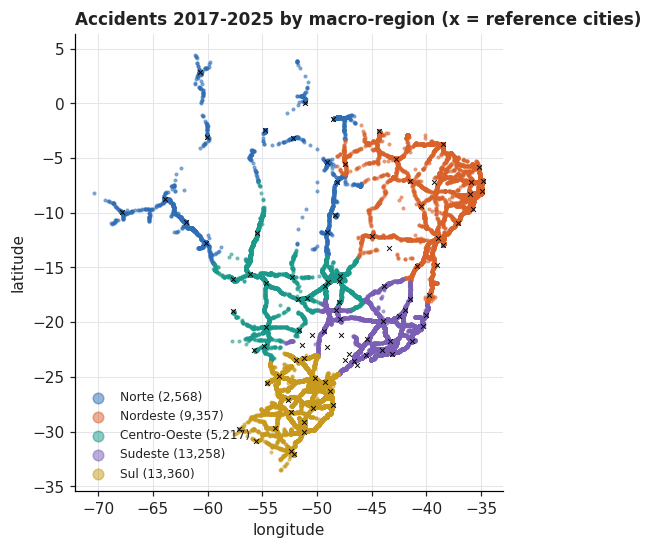

In [13]:
# Keep the modelling years that have coordinates, and drop the invalid coordinates (see section 2.2)
geo = raw[raw["date"] >= "2017-01-01"].dropna(subset=["latitude", "longitude"]).copy()
geo["valid_coord"] = geo["latitude"].between(-34, 6) & geo["longitude"].between(-74, -32)
print(f"2017-2025 rows with coordinates: {len(geo):,} | invalid coordinates removed: {(~geo.valid_coord).sum()}")
acc_region = geo[geo.valid_coord].copy()

acc_region["region"], acc_region["dist_km"], acc_region["border_gap_km"] = assign_region(
    acc_region["latitude"].values, acc_region["longitude"].values)
acc_region.loc[acc_region["dist_km"] > MAX_ANCHOR_KM, "region"] = np.nan
acc_region["region_en"] = acc_region["region"].map(REGION_EN)

print(f"points with no region (too far from every city): {acc_region.region.isna().sum()}")
print(f"points within 30 km of a regional border (could be on the wrong side): {(acc_region.border_gap_km < 30).mean():.1%}")

fig, ax = plt.subplots(figsize=(5.6, 5.4))
for r in REGIONS:
    s = acc_region[acc_region.region == r]
    ax.scatter(s.longitude, s.latitude, s=3, color=REGION_COLORS[r], label=f"{r} ({len(s):,})", alpha=0.5)
ax.scatter(anchors.lon, anchors.lat, s=10, color="black", marker="x", linewidths=0.6)
ax.set(title="Accidents 2017-2025 by macro-region (x = reference cities)",
       xlabel="longitude", ylabel="latitude", aspect="equal")
ax.legend(markerscale=4, fontsize=8, loc="lower left")
plt.show()

Saved data/processed/accidents_region.csv: 43,760 rows


,victim_accidents,fatal_%,per_day
region,,,
Norte,1750,13.371,0.618
Nordeste,6454,12.209,2.280
Centro-Oeste,3486,8.692,1.231
Sudeste,9314,6.571,3.290
Sul,8853,6.856,3.127


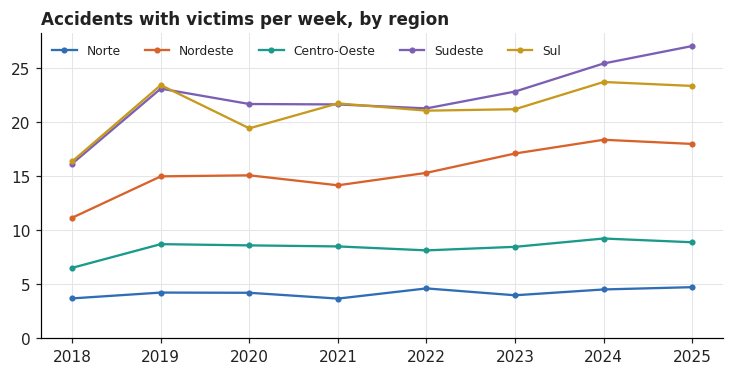

In [14]:
# Save a small table that colleagues can join to the calendar and to the weather (on region_en and date)
acc_region["is_victim"] = (acc_region["accident_classification"] >= 1).astype(int)
acc_region["is_fatal"] = (acc_region["accident_classification"] == 2).astype(int)
acc_region_out = acc_region.dropna(subset=["region"])[
    ["date", "region", "region_en", "latitude", "longitude", "accident_classification", "is_victim", "is_fatal"]]
acc_region_out.to_csv(OUT / "accidents_region.csv", index=False)
print(f"Saved {OUT / 'accidents_region.csv'}: {len(acc_region_out):,} rows")

# Region summary (accidents with victims only, from the stable coding period)
# fatal_% = share of the victim accidents that had a death
v = acc_region_out[(acc_region_out.is_victim == 1) & (acc_region_out.date >= ERA_START)]
weeks = (pd.Timestamp("2025-12-31") - ERA_START).days / 7
summary = v.groupby("region").agg(victim_accidents=("is_victim", "size"), fatal_share=("is_fatal", "mean")).reindex(REGIONS)
summary["per_day"] = summary["victim_accidents"] / (weeks * 7)
summary["fatal_share"] = summary["fatal_share"] * 100
summary = summary.rename(columns={"fatal_share": "fatal_%"})
display(summary)

# Accidents with victims per week, by region and year
per_week = (v.assign(year=v.date.dt.year).groupby(["year", "region"]).size().unstack()[REGIONS] / 52)
fig, ax = plt.subplots()
for r in REGIONS:
    ax.plot(per_week.index, per_week[r], color=REGION_COLORS[r], marker="o", ms=3, label=r)
ax.set(title="Accidents with victims per week, by region", ylim=(0, None))
ax.legend(ncol=5, fontsize=8)
plt.show()

**Reading**

- **Regions are very different in size.** Sudeste and Sul have about 3 accidents with victims per day. Norte has about 0.6 per day, which is less than one a day. Because the counts are small, we predict a count and not a yes or no.
- **Fatal share is higher in Norte (13%) and Nordeste (12%)** than in Sudeste and Sul (about 7%). So region also tells us how serious the accidents are.
- **The border error is small.** Only 1.3% of points are within 30 km of a regional border. No valid point was rejected for being too far from a city.
- **Limit:** the nearest city is only an approximation. Future work: use the official IBGE state borders, and move from 5 regions to 27 states.

**Decision:** region = region of the nearest reference city. We keep two names: `region` (Portuguese, used in this notebook) and `region_en` (English, the same names as in the weather tables), so colleagues can join on `region_en` and `date`.